# Module 2 · Partie 3 : La régression sur composantes principales (PCR)

> Cours d'**Analyse multivariée 2 : Data Mining & Machine Learning** (Prof. H. Soyeurt, Gembloux Agro-Bio Tech, 2026-2027).
> Sources : syllabus *Validation, PCR and PLS* (`module2.pdf`, §2), exercice dirigé officiel *PLS_PCR_fatty_acids_20201007.Rmd* (§3), script `pcr_fatty_acids.R`.

### Objectifs d'apprentissage
À la fin de ce notebook, tu sauras :
1. expliquer pourquoi la PCR permet de faire une régression **malgré la colinéarité** et **même si p > n** ;
2. réaliser une PCR **à la main** en trois phases (ACP, régression sur les composantes, retour aux variables d'origine) et retrouver les résultats de `pls::pcr()` ;
3. utiliser le package `pls` : `pcr()`, `summary()`, `R2()`, `RMSEP()`, `validationplot()`, `predplot()`, `coefplot()`, `predict()`, `selectNcomp()` ;
4. choisir le **nombre de composantes** par validation croisée (RMSE minimal, différence de robustesse, différence de précision) ;
5. citer les **avantages** et le principal **inconvénient** de la PCR.

### Prérequis
Partie 1 (validation croisée), partie 2 (ACP, GH), module 1 (régression multivariée, colinéarité).

### Sommaire
- 3.1 Le problème : colinéarité et p > n (exemple « octane »)
- 3.2 Méthodologie de la PCR
- 3.3 La PCR à la main en trois phases
- 3.4 Le package `pls` en détail
- 3.5 Choisir le nombre de composantes par validation croisée
- 3.6 Avantages et inconvénients
- 3.7 Application : acides gras saturés du lait (exercice dirigé)
- Questions de compréhension
- Récapitulatif

In [1]:
# Packages utilisés dans ce notebook
suppressPackageStartupMessages({
  library(pls)         # pcr(), RMSEP(), R2(), validationplot()...
  library(FactoMineR)  # PCA() pour le nettoyage GH (comme le Rmd officiel)
  library(ggplot2)     # graphiques R2/RMSE du Rmd officiel
  library(reshape2)    # melt()
  library(knitr)       # kable()
})
options(repr.plot.width = 10, repr.plot.height = 6)  # taille des figures dans Jupyter

---
## 3.1 Le problème : colinéarité et p > n

La PCR (*Principal Component Regression*) permet de construire une régression à partir d'un jeu de données :
- comptant **moins d'observations que de variables explicatives** ($n < p$) ;
- dont certaines variables explicatives sont **fortement corrélées** entre elles (colinéarité).

Ce sont exactement les deux situations où la régression linéaire classique (MCO) échoue (module 1 : $(X'X)^{-1}$ n'existe pas ou est instable).

### L'exemple du syllabus : l'indice d'octane
On a mesuré l'indice d'octane (*y*) de 12 mélanges pour étudier l'influence de 7 composants (Table 1 du syllabus).

In [2]:
# Table 1 du syllabus (module2.pdf, §2.1)
octane <- data.frame(
  X1 = c(0, 0, 0, 0, 0, 0, 0.17, 0.17, 0.17, 0.17, 0.21, 0),
  X2 = c(0.23, 0.1, 0, 0.49, 0, 0.62, 0.27, 0.19, 0.21, 0.15, 0.36, 0),
  X3 = c(0, 0, 0, 0, 0, 0, 0.1, 0.1, 0.1, 0.1, 0.12, 0),
  X4 = c(0, 0, 0.1, 0, 0.62, 0, 0.38, 0.38, 0.38, 0.38, 0.25, 0.55),
  X5 = c(0, 0.12, 0.12, 0.12, 0.12, 0, 0, 0.02, 0, 0.02, 0, 0),
  X6 = c(0.74, 0.74, 0.74, 0.37, 0.18, 0.37, 0, 0.06, 0.06, 0.1, 0, 0.37),
  X7 = c(0.03, 0.04, 0.04, 0.02, 0.08, 0.01, 0.08, 0.08, 0.08, 0.08, 0.06, 0.08),
  octane = c(98.7, 97.8, 96.6, 92, 86.6, 91.2, 81.9, 83.1, 82.4, 83.2, 81.4, 88.1))
round(cor(octane[, 1:7]), 2)      # matrice de corrélation du syllabus

,X1,X2,X3,X4,X5,X6,X7
X1,1.00,0.10,1.00,0.37,-0.55,-0.80,0.60
X2,0.10,1.00,0.10,-0.54,-0.29,-0.19,-0.59
X3,1.00,0.10,1.00,0.37,-0.55,-0.81,0.61
X4,0.37,-0.54,0.37,1.00,-0.21,-0.65,0.92
X5,-0.55,-0.29,-0.55,-0.21,1.00,0.46,-0.27
X6,-0.80,-0.19,-0.81,-0.65,0.46,1.00,-0.66
X7,0.60,-0.59,0.61,0.92,-0.27,-0.66,1.00


On retrouve la matrice de corrélation du syllabus : X1 et X3 sont **parfaitement** corrélées (1.00), X4 et X7 à 0.92, X1/X3 et X6 à −0.80… Il y a donc des problèmes de colinéarité, et il faut une méthode qui **réduit la dimension** de la matrice X.

Il y a même pire : ce sont des **proportions** de mélange, qui somment à 1 pour chaque mélange. Une des variables est une combinaison exacte des autres (avec l'intercept), et la régression classique ne peut pas estimer tous les coefficients :

In [3]:
rowSums(octane[, 1:7])                    # chaque mélange : somme des proportions = 1
reg_mco <- lm(octane ~ ., data = octane)
summary(reg_mco)$coefficients             # X7 absent : "not defined because of singularities"
summary(reg_mco)$r.squared

[1] 1 1 1 1 1 1 1 1 1 1 1 1

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),116.92128,81.09563,1.4417705,0.2089390
X1,-82.60105,173.21740,-0.4768635,0.6535720
X2,-30.99845,80.83864,-0.3834608,0.7171412
X3,24.33065,431.97280,0.0563245,0.9572648
X4,-39.74118,90.24604,-0.4403648,0.6780591
X5,-29.17106,84.01584,-0.3472091,0.7425712
X6,-16.62045,84.45229,-0.1968028,0.8517314


[1] 0.9925265

La régression MCO perd X7 (coefficient `NA`), et **aucun** des coefficients restants n'est significatif malgré un R² de 0.9925 : c'est le symptôme typique de la colinéarité vu au module 1.

---
## 3.2 Méthodologie de la PCR

La PCR combine la **théorie de la régression linéaire** et l'**analyse en composantes principales** (partie 2). L'idée repose sur une propriété de l'ACP : les composantes principales sont **orthogonales**, donc **non corrélées** entre elles. Si on les utilise comme variables explicatives, il n'y a plus de colinéarité.

La régression classique s'écrit (module 1) :
$$y = X\beta + e$$

La PCR remplace $X$ par la matrice de ses composantes principales :
$$y = X_{PCR}\,\beta + e$$

où $X_{PCR}$ contient les composantes principales de la matrice X initiale. Sa taille dépend du **nombre de composantes choisies** ($k \le p$). Grâce aux vecteurs propres, on peut ensuite **revenir à l'échelle initiale**.

La méthode se déroule donc en **3 phases** (syllabus §2.2) :
1. réaliser une **ACP** sur les variables explicatives (centrées réduites) ;
2. réaliser une **régression linéaire** de y sur les $k$ premières composantes principales ;
3. à l'aide des **vecteurs propres**, faire une transformation inverse pour obtenir les coefficients des **variables explicatives initiales**.

> **Complément** (la phase 3 en formules) : si $X_s$ est la matrice centrée réduite et $U_k$ la matrice des $k$ premiers vecteurs propres, les scores sont $Z_k = X_s U_k$. La régression donne $\hat y = \gamma_0 + Z_k\gamma$. Comme $Z_k\gamma = X_s (U_k\gamma)$, les coefficients des variables **réduites** sont $\beta_s = U_k\gamma$. Pour les variables d'**origine** : $\beta_j = \beta_{s,j}/s_j$ et l'intercept vaut $\beta_0 = \gamma_0 - \sum_j \beta_j \bar x_j$.

> **Définition** : en PCR, $k$ est l'**hyperparamètre** du modèle. Avec $k = p$ composantes (et des variables sans colinéarité parfaite), la PCR redonne exactement la régression MCO. Avec $k < p$, on écarte les directions de faible variance de X, celles qui rendent les MCO instables.

---
## 3.3 La PCR à la main en trois phases

In [4]:
X_oct <- as.matrix(octane[, 1:7])
y_oct <- octane$octane

# Phase 1 : ACP sur les variables centrées réduites
Xs <- scale(X_oct)                    # centrage-réduction (écart-type en n-1)
e  <- eigen(cor(X_oct))               # vecteurs propres (U) et valeurs propres
Z  <- Xs %*% e$vectors                # scores = composantes principales
round(100 * cumsum(e$values) / 7, 2)  # % cumulé de variance de X

[1]  57.51  84.80  92.98  99.81 100.00 100.00 100.00

In [5]:
# Phase 2 : régression de y sur les k premières composantes (ici k = 3)
k <- 3
reg_pc <- lm(y_oct ~ Z[, 1:k])
coef(reg_pc)                          # gamma0, gamma1, gamma2, gamma3
summary(reg_pc)$r.squared             # part de la variance de y expliquée avec 3 composantes

(Intercept)   Z[, 1:k]1   Z[, 1:k]2   Z[, 1:k]3 
 88.5833333   3.0782512  -0.4763109   0.9261857

[1] 0.9186878

In [6]:
# Phase 3 : retour aux variables d'origine grâce aux vecteurs propres
gamma   <- coef(reg_pc)[-1]
beta_s  <- e$vectors[, 1:k] %*% gamma                  # coefficients des variables réduites
beta    <- beta_s / attr(Xs, "scaled:scale")           # coefficients des variables d'origine
beta0   <- coef(reg_pc)[1] - sum(beta * attr(Xs, "scaled:center"))
coef_main <- c("(Intercept)" = unname(beta0), setNames(as.vector(beta), colnames(X_oct)))
round(coef_main, 3)

# Vérification : l'équation sur les variables d'origine donne les mêmes prédictions
all.equal(as.vector(beta0 + X_oct %*% beta), unname(fitted(reg_pc)))

(Intercept)          X1          X2          X3          X4          X5 
     92.803     -18.858      -1.017     -32.330      -3.277       4.272 
         X6          X7 
      5.568     -40.301

[1] TRUE

On a obtenu une **équation sur les 7 composants d'origine**, avec 7 coefficients non nuls, alors que la régression MCO ne pouvait même pas estimer X7. On compare maintenant avec la fonction `pcr()` du package `pls`.

In [7]:
m_oct <- pcr(octane ~ ., data = octane, scale = TRUE)
summary(m_oct)

Data: 	X dimension: 12 7 
	Y dimension: 12 1
Fit method: svdpc
Number of components considered: 7
TRAINING: % variance explained
        1 comps  2 comps  3 comps  4 comps  5 comps  6 comps  7 comps
X         57.51    84.80    92.98    99.81   100.00   100.00   100.00
octane    89.69    90.71    91.87    99.06    99.25    99.25    99.74


On retrouve la **Table 2** du syllabus :

| | 1 comps | 2 comps | 3 comps | 4 comps | 5 comps | 6 comps | 7 comps |
|---|---|---|---|---|---|---|---|
| X (syllabus) | 57.51 | 84.80 | 92.98 | 99.81 | 100.00 | 100.00 | 100.0 |
| Y (syllabus) | 89.69 | 90.71 | 91.87 | 99.06 | 99.25 | 99.25 | 99.3 |

Le syllabus en conclut que **5 composantes décrivent 100 % de la variabilité de X et 99.25 % de la variabilité de y** (le R²).

> **Attention** (écart avec le syllabus) : à 7 composantes, `pcr()` affiche ici 99.74 % pour y, le syllabus 99.3 %. Aucune des deux valeurs n'a de sens : la 7e valeur propre est **nulle** (les proportions somment à 1, voir 3.1), la 7e « composante » ne contient que des erreurs d'arrondi numérique et la régression sur elle ajuste du bruit. Le vrai maximum est le R² des MCO, **99.25 %**, atteint dès 5 composantes. Cela illustre une règle : on n'utilise jamais les composantes de variance (quasi) nulle.

In [8]:
# Comparaison de nos coefficients "à la main" avec ceux de pcr() pour 3 composantes
b_pls <- coef(m_oct, ncomp = 3, intercept = TRUE)[, 1, 1]
round(cbind(main = coef_main, pcr_brut = b_pls,
            pcr_corrige = c(b_pls[1], b_pls[-1] / m_oct$scale)), 3)

,main,pcr_brut,pcr_corrige
(Intercept),92.803,92.803,92.803
X1,-18.858,-1.740,-18.858
X2,-1.017,-0.199,-1.017
X3,-32.330,-1.740,-32.330
X4,-3.277,-0.744,-3.277
X5,4.272,0.244,4.272
X6,5.568,1.631,5.568
X7,-40.301,-1.091,-40.301


> **Attention** (piège du package `pls`) : avec `scale = TRUE`, `coef()` renvoie les coefficients des variables **réduites** (divisées par leur écart-type), alors que l'intercept est celui de l'équation sur les variables d'**origine**. Pour obtenir l'équation applicable aux données brutes, il faut diviser les coefficients par `m$scale` (les écarts-types utilisés). La fonction `predict()`, elle, gère cette mise à l'échelle automatiquement : c'est la méthode à privilégier pour prédire.

### Exercice 3.1 : la PCR à 4 et 5 composantes
1. Refais les phases 2 et 3 avec $k = 4$ puis $k = 5$. Compare le R² obtenu avec la ligne *octane* de `summary(m_oct)`.
2. Vérifie que tes coefficients d'origine pour $k = 4$ sont égaux à `coef(m_oct, ncomp = 4) / m_oct$scale`.

In [9]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
pcr_main <- function(k) {
  reg <- lm(y_oct ~ Z[, 1:k, drop = FALSE])
  b <- (e$vectors[, 1:k, drop = FALSE] %*% coef(reg)[-1]) / attr(Xs, "scaled:scale")
  list(R2 = summary(reg)$r.squared, beta = as.vector(b))
}
r4 <- pcr_main(4); r5 <- pcr_main(5)
c(R2_k4 = r4$R2, R2_k5 = r5$R2)       # 0.9906 et 0.9925 : lignes 4 et 5 comps de summary()
all.equal(r4$beta, unname(coef(m_oct, ncomp = 4)[, 1, 1] / m_oct$scale))
```

Avec 4 composantes, on explique 99.06 % de la variance de l'indice d'octane ; avec 5, 99.25 %, soit le maximum (R² des MCO). La fonction `pcr_main()` généralise les phases 2 et 3 à n'importe quel nombre de composantes.

</details>

### Exercice 3.2 : les composantes ne sont pas rangées selon y
Calcule la corrélation au carré entre l'indice d'octane et **chacune** des 7 composantes (`cor(Z, y_oct)^2`). L'ordre des composantes (rangées par variance de X décroissante) correspond-il à leur pouvoir explicatif de y ?

In [10]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
round(cor(Z, y_oct)^2, 3)
```

La CP1 explique 89.7 % de la variance de y, mais la CP4, qui ne porte que 6.8 % de la variance de X, en explique à elle seule environ 7 % (c'est le saut de 91.87 % à 99.06 % dans la Table 2), alors que les CP2 et CP3 n'apportent presque rien. L'ordre des composantes est fixé par **X seulement**, pas par y. C'est précisément l'inconvénient de la PCR (section 3.6), et ce que la PLS corrige (partie 4).

</details>

---
## 3.4 Le package `pls` en détail

> **Fonction R** : `pcr(formula, ncomp, data, scale = FALSE, center = TRUE, validation = c("none", "CV", "LOO"), segments = 10, segment.type = "random", ...)`
>
> | Argument | Rôle |
> |---|---|
> | `formula` | `y ~ .` (toutes les colonnes de `data`) ou `y ~ spectra` (une matrice stockée dans le data.frame) |
> | `ncomp` | nombre **maximal** de composantes calculées (toutes si absent) |
> | `data` | data.frame contenant y et les X |
> | `scale` | `TRUE` : variables réduites (même poids pour toutes, comme l'ACP normée). **Défaut `FALSE`** : à préciser ! |
> | `center` | centrage des variables (`TRUE` par défaut) |
> | `validation` | `"CV"` : validation croisée k-fold (10 segments aléatoires par défaut) ; `"LOO"` : leave-one-out ; `"none"` |
> | `segments` | nombre de segments (ou liste d'indices, cf. `cvsegments()`) |
>
> **Renvoie** un objet de classe `"mvr"` : `$coefficients` (tableau 3D variables × réponses × nb de composantes), `$scores`, `$loadings`, `$Xmeans`, `$Ymeans`, `$scale`, `$fitted.values`, `$residuals`, `$Xvar`, `$Xtotvar`, `$validation` (prédictions CV). `pcr()` est un raccourci pour `mvr(..., method = "svdpc")` ; `plsr()` (partie 4) utilise la même structure.

**Les fonctions qui exploitent un objet `mvr`** :

| Fonction | Rôle |
|---|---|
| `summary(m)` | RMSEP de validation croisée (si `validation`) et % de variance expliquée de X et y |
| `explvar(m)` | % de variance de X expliquée par chaque composante |
| `R2(m, estimate)` / `RMSEP(m, estimate)` | R² / RMSE par nombre de composantes ; `estimate = "train"` (calibration), `"CV"`, `"adjCV"`, `"test"` ou `"all"` |
| `validationplot(m, val.type)` | courbe RMSEP, MSEP ou R2 en fonction du nombre de composantes |
| `predplot(m, ncomp, which)` | valeurs prédites vs mesurées (`which = "train"` ou `"validation"`) |
| `coefplot(m, ncomp)` | coefficients de régression (utile le long d'un spectre) |
| `scoreplot(m)`, `loadingplot(m)` | scores et loadings des composantes |
| `predict(m, newdata, ncomp)` | prédictions (tableau 3D : individus × réponses × composantes) |
| `selectNcomp(m, method)` | choix automatique du nombre de composantes (`"onesigma"`, `"randomization"`) |

### La structure des objets `R2()` et `RMSEP()`

In [11]:
r_oct <- RMSEP(m_oct, estimate = "train")
dimnames(r_oct$val)          # 3 dimensions : estimate x response x model
round(r_oct$val[1, 1, ], 3)  # 1re valeur = "(Intercept)" : modèle sans composante (y prédit par sa moyenne)
round(r_oct$val[1, 1, -1], 3)   # [-1] pour retirer l'intercept et garder 1 à 7 composantes

$estimate
[1] "train"

$response
[1] "octane"

$model
[1] "(Intercept)" "1 comps"     "2 comps"     "3 comps"     "4 comps"    
[6] "5 comps"     "6 comps"     "7 comps"

(Intercept)     1 comps     2 comps     3 comps     4 comps     5 comps 
      6.244       2.004       1.903       1.780       0.607       0.542 
    6 comps     7 comps 
      0.540       0.320

1 comps 2 comps 3 comps 4 comps 5 comps 6 comps 7 comps 
  2.004   1.903   1.780   0.607   0.542   0.540   0.320

> **Attention** : dans `$val`, la première position du troisième indice est le modèle **« (Intercept) »** (0 composante). Pour lire la valeur à $k$ composantes, il faut donc prendre l'indice $k + 1$, ou retirer l'intercept avec `[-1]` comme dans les scripts (`RMSEP(...)$val[1, 1, -1]`).

---
## 3.5 Choisir le nombre de composantes par validation croisée

Le syllabus le dit simplement : **le nombre de composantes à considérer est estimé par validation croisée**. En calibration, plus on ajoute de composantes, plus le R² augmente et plus le RMSE diminue (jusqu'au surapprentissage). En validation croisée (partie 1), le RMSE diminue puis remonte.

Avec seulement 12 mélanges, on utilise une validation croisée **leave-one-out** (*full cross-validation*).

In [12]:
m_oct_cv <- pcr(octane ~ ., data = octane, scale = TRUE, validation = "LOO")
round(RMSEP(m_oct_cv, estimate = c("train", "CV"))$val[, 1, ], 3)

,(Intercept),1 comps,2 comps,3 comps,4 comps,5 comps,6 comps,7 comps
train,6.244,2.004,1.903,1.780,0.607,0.542,5.40000e-01,3.200000e-01
CV,6.811,2.299,2.537,2.744,1.312,1.431,2.22461e+13,3.727368e+13


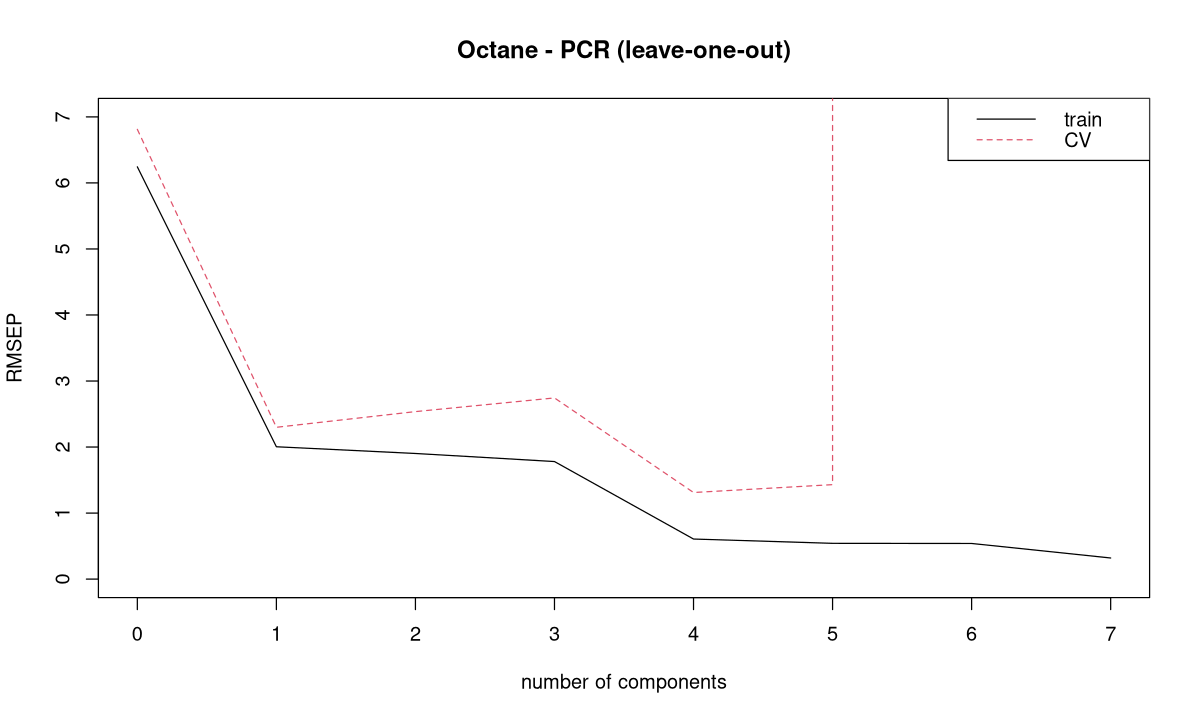

In [13]:
validationplot(m_oct_cv, val.type = "RMSEP", estimate = c("train", "CV"),
               legendpos = "topright", ylim = c(0, 7), main = "Octane - PCR (leave-one-out)")

- En calibration (*train*), le RMSE ne fait que diminuer.
- En validation croisée, le RMSE est minimal à **4 composantes** (1.31), puis remonte. À 6 et 7 composantes, il **explose** (de l'ordre de $10^{13}$, hors du graphique) : ces composantes ont une variance nulle ou quasi nulle, et la régression sur elles est numériquement instable. C'est la démonstration par l'absurde qu'il ne faut pas garder les dernières composantes.

[1] 4

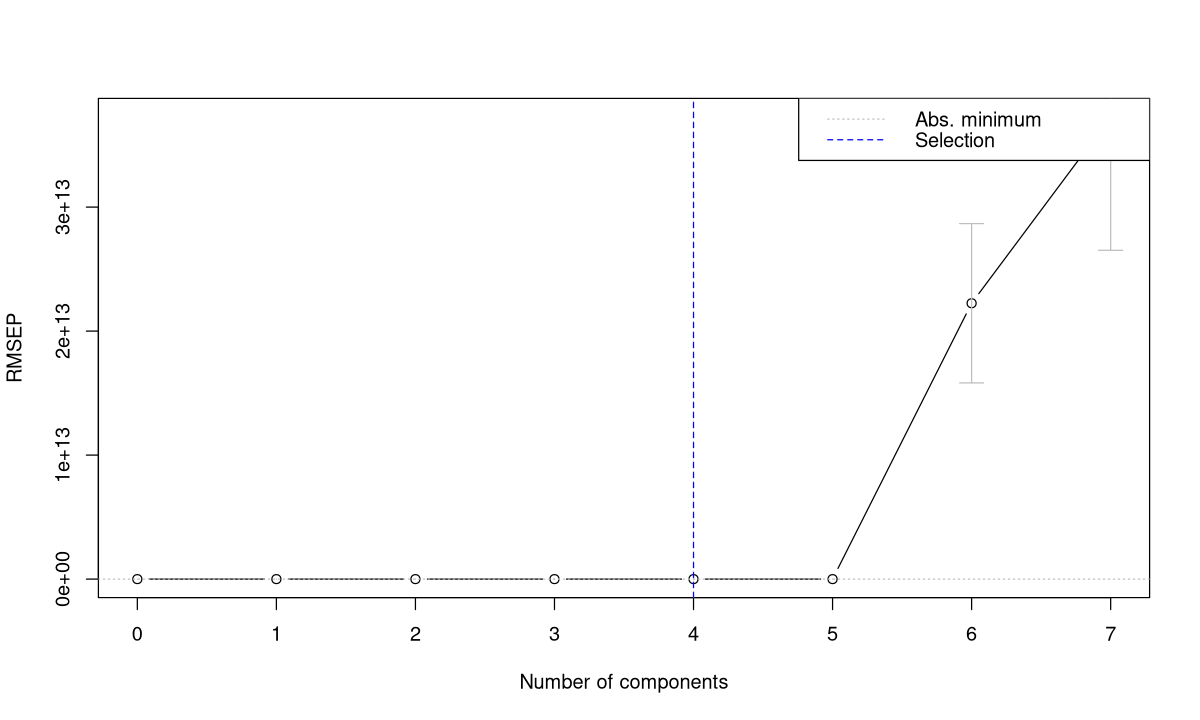

In [14]:
suppressWarnings(selectNcomp(m_oct_cv, method = "onesigma", plot = TRUE))   # avertissements graphiques sans importance

> **Fonction R** : `selectNcomp(object, method = c("randomization", "onesigma"), nperm = 999, alpha = 0.01, ncomp, plot = FALSE)`
> - `"onesigma"` : le **plus petit** nombre de composantes dont le RMSE de validation croisée est à moins d'**un écart-type** du minimum (règle du « 1 SE », comme `lambda.1se` de `cv.glmnet`) ;
> - `"randomization"` : test par permutations : on garde le plus petit modèle dont l'erreur n'est pas significativement plus grande que celle du minimum (Van der Voet).
>
> Ces deux règles favorisent les modèles **parcimonieux**.

### Exercice 3.3 : validation croisée en 4 segments
Refais la PCR de l'octane avec `validation = "CV", segments = 4` (fixe d'abord `set.seed(1)`). Le nombre de composantes optimal change-t-il ? Recommence avec `set.seed(2)`. Qu'en conclus-tu ?

In [15]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
for (s in 1:2) {
  set.seed(s)
  m_cv4 <- pcr(octane ~ ., data = octane, scale = TRUE, validation = "CV", segments = 4)
  rmse_cv <- RMSEP(m_cv4, estimate = "CV")$val[1, 1, -1]
  print(round(rmse_cv[1:5], 3))
  print(which.min(rmse_cv))
}
```

Avec seulement 12 observations, le découpage aléatoire en segments change les résultats d'un tirage à l'autre. C'est pourquoi on fixe toujours la graine (`set.seed(1001)` dans le Rmd officiel) pour que les résultats soient reproductibles, et pourquoi le homework 2 répète la validation croisée plusieurs fois (partie 1).

</details>

---
## 3.6 Avantages et inconvénients

**Avantages** (syllabus §2.3) :
- **résoudre les problèmes de colinéarité** entre variables explicatives (les composantes sont non corrélées) ;
- permettre de construire une régression **même si le nombre de variables explicatives est supérieur au nombre d'observations**.

**Inconvénient principal** : la décomposition qui réduit la dimension de X est basée sur la **variabilité de X** et **pas sur celle de y**, qui est pourtant celle qui nous intéresse le plus dans un modèle de prédiction. Une composante de grande variance peut n'avoir aucun lien avec y, et une composante de faible variance peut être très prédictive (exercice 3.2). Il faut alors garder beaucoup de composantes pour « attraper » l'information utile.

> **Complément** : c'est exactement la motivation de la **PLS** (partie 4), qui construit des variables latentes en maximisant leur **covariance avec y**.

> **Complément** : l'interprétation des composantes principales a été vue dans le cours d'Analyse multivariée 1 (STAT1213). En PCR, on interprète surtout les **coefficients de régression sur les variables d'origine** (phase 3), par exemple le long d'un spectre avec `coefplot()`.

---
## 3.7 Application : acides gras saturés du lait (exercice dirigé)

On reprend la démarche du Rmd officiel (§3) : prédire la teneur en acides gras saturés (SAT, g/dl de lait) à partir des 1 060 points du spectre MIR, sur le jeu **nettoyé des outliers spectraux** (partie 2).

### 3.7.1 Données et nettoyage (rappel de la partie 2)

In [16]:
fattyacid <- read.table(file = "../fatty_acids.csv", sep = ";", header = TRUE)
x <- fattyacid[, 5:1064]          # spectre
y <- fattyacid[, 2]               # SAT

# Outliers spectraux : ACP normée, 47 composantes, GH = Mahalanobis / 47 (partie 2)
nPC <- 47
res_pca <- PCA(x, scale.unit = TRUE, ncp = nPC, graph = FALSE)
maha <- mahalanobis(res_pca$ind$coord, center = colMeans(res_pca$ind$coord),
                    cov = cov(res_pca$ind$coord))
GH <- maha / nPC
newX <- x[GH < 3, ]
newy <- y[GH < 3]
c(n_initial = nrow(x), n_retire = sum(GH >= 3), n_calibration = nrow(newX))

n_initial      n_retire n_calibration 
          485             3           482

### 3.7.2 Le modèle PCR avec validation croisée

Pour simplifier l'écriture de la formule, le Rmd crée un `data.frame` avec des noms de colonnes explicites (`SAT`, `SPEC1` … `SPEC1060`).

In [17]:
# Création du data.frame (code du Rmd officiel)
calibration <- data.frame(newy, newX)
names(calibration) <- c("SAT", paste0("SPEC", 1:1060))

# Modèle PCR : 10-fold CV, jusqu'à 70 composantes
set.seed(1001)    # pour que le découpage de la validation croisée soit reproductible
PCR <- pcr(SAT ~ ., data = calibration, scale = TRUE, center = TRUE,
           validation = "CV", ncomp = 70)
PCR

Principal component regression, fitted with the singular value decomposition algorithm.
Cross-validated using 10 random segments.
Call:
pls::pcr(formula = SAT ~ ., ncomp = 70, data = calibration, scale = TRUE,     center = TRUE, validation = "CV")

> **Attention** : le texte du Rmd parle de « la fonction **PCR()** », mais la fonction s'appelle `pcr()` en minuscules. `PCR` (en majuscules) est seulement le nom de l'objet créé. R distingue les majuscules des minuscules.

`summary(PCR)` affiche deux blocs pour les 70 composantes (sortie très longue) :
- **VALIDATION: RMSEP** : le RMSE de validation croisée (`CV`) et sa version corrigée du biais (`adjCV`) ;
- **TRAINING: % variance explained** : la part de variance de X et de SAT expliquée en calibration.

On en affiche un extrait :

In [18]:
# Extrait du summary : RMSEP de CV et % de variance pour 1 à 15 composantes
round(RMSEP(PCR, estimate = c("CV", "adjCV"))$val[, 1, 1:16], 4)
round(rbind(X = cumsum(explvar(PCR))[1:15],
            SAT = 100 * R2(PCR, estimate = "train")$val[1, 1, 2:16]), 2)

,(Intercept),1 comps,2 comps,3 comps,4 comps,5 comps,6 comps,7 comps,8 comps,9 comps,10 comps,11 comps,12 comps,13 comps,14 comps,15 comps
CV,0.8544,0.4323,0.2773,0.2700,0.2689,0.2665,0.2585,0.2545,0.2425,0.2395,0.2379,0.2379,0.2377,0.2384,0.2381,0.2335
adjCV,0.8544,0.4318,0.2772,0.2699,0.2687,0.2663,0.2583,0.2539,0.2420,0.2392,0.2374,0.2375,0.2374,0.2383,0.2387,0.2331


,Comp 1,Comp 2,Comp 3,Comp 4,Comp 5,Comp 6,Comp 7,Comp 8,Comp 9,Comp 10,Comp 11,Comp 12,Comp 13,Comp 14,Comp 15
X,43.03,68.21,80.51,84.49,86.97,88.65,89.58,90.44,91.20,91.81,92.34,92.79,93.19,93.57,93.92
SAT,74.87,89.57,90.11,90.26,90.50,91.13,91.54,92.24,92.48,92.63,92.63,92.64,92.65,92.79,93.05


On retrouve les valeurs du Rmd : la première composante explique 43.03 % de la variabilité spectrale et 74.87 % de celle de SAT ; avec 10 composantes, 91.81 % de X et 92.63 % de SAT.

### 3.7.3 Performances de calibration et de validation croisée

Les fonctions `R2()` et `RMSEP()` avec `"all"` renvoient la calibration (`train`), la validation croisée (`CV`) et sa version ajustée (`adjCV`). Le Rmd les représente avec `ggplot2` après les avoir « fondues » en tableau long avec `melt()`.

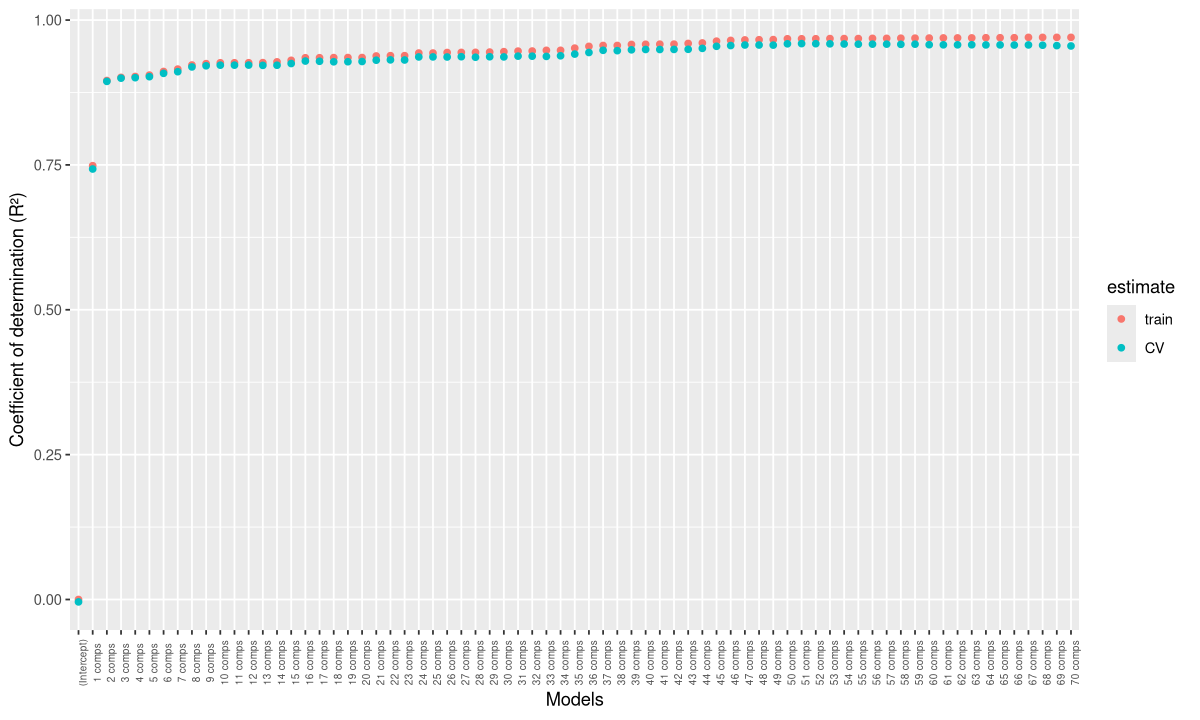

In [19]:
Rsquare <- R2(PCR, "all")                     # R2 de calibration et de validation croisée
melted_R2 <- melt(Rsquare$val)                # tableau long : estimate, response, model, value
ggplot(data = melted_R2) + aes(x = model, y = value, col = estimate) + geom_point() +
  xlab("Models") + ylab("Coefficient of determination (R²)") +
  theme(axis.text.x = element_text(size = 6, angle = 90))

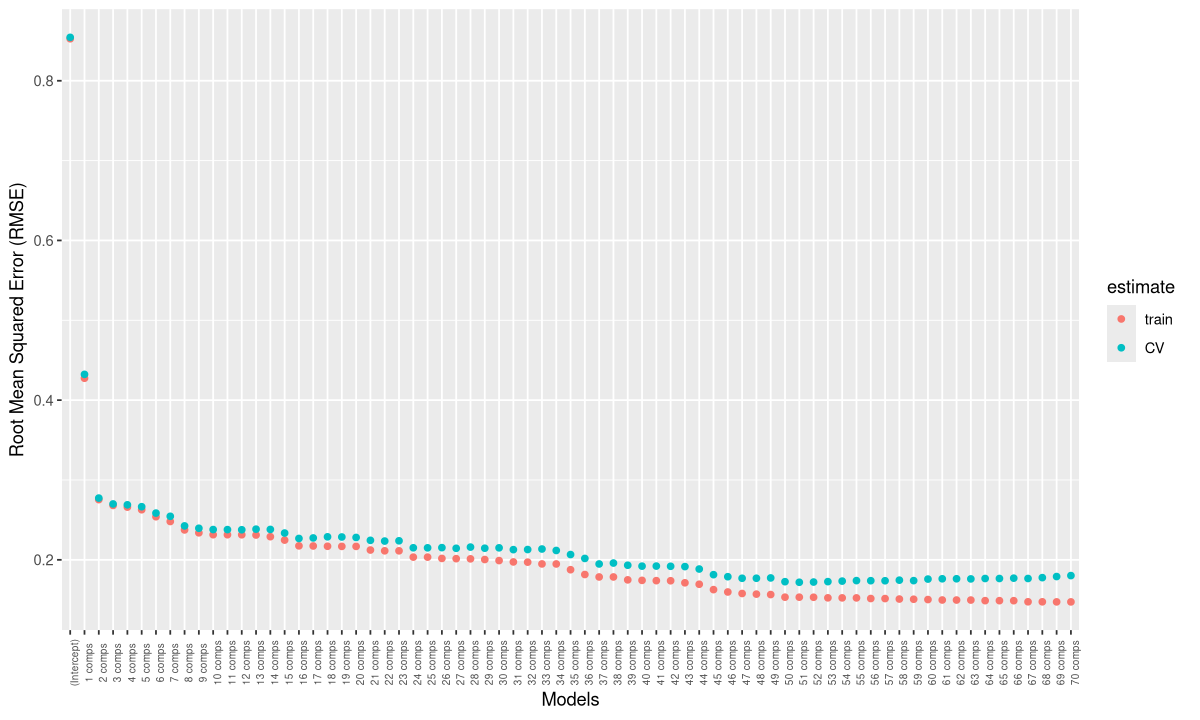

In [20]:
RMSEP_PCR <- RMSEP(PCR, "all")                # RMSE de calibration et de validation croisée
melted_RMSE <- melt(RMSEP_PCR$val[1:2, , ])   # 1:2 = train et CV seulement
ggplot(data = melted_RMSE) + aes(x = model, y = value, col = estimate) + geom_point() +
  xlab("Models") + ylab("Root Mean Squared Error (RMSE)") +
  theme(axis.text.x = element_text(size = 6, angle = 90))

> **Attention** : dans le Rmd, l'objet est appelé `RMSEP`, comme la fonction `RMSEP()`. Ça fonctionne (R cherche une **fonction** quand on écrit `RMSEP(...)`), mais c'est une source de confusion : on l'appelle ici `RMSEP_PCR`.

On observe, à un moment, le **surapprentissage** : l'erreur de calibration diminue sans cesse quand on ajoute des composantes, mais l'écart entre calibration et validation croisée grandit, et le RMSE de validation croisée finit par remonter (fin du graphe).

### 3.7.4 Trois règles pour choisir le nombre de composantes

Le Rmd officiel propose trois critères :

1. **le RMSE de validation croisée le plus bas** : malheureusement, il est souvent atteint pour un très grand nombre de composantes ;
2. **la plus petite différence entre calibration et validation croisée** (*robustness diff*) : plus elle est faible, plus le modèle est robuste ;
3. **la plus petite différence entre les résultats de validation croisée de deux modèles consécutifs** (*accuracy diff*) : si ajouter une composante n'améliore presque plus le R² ou le RMSE, on préfère le modèle le plus parcimonieux.

In [21]:
# Tableau de performances du Rmd officiel
difference <- Rsquare$val[1, , ] - Rsquare$val[2, , ]            # robustness diff : R2 cal - R2 CV
difference2 <- array(0, dim = c(length(difference)))
for (i in 2:length(difference)) {
  difference2[i] <- Rsquare$val[2, , i] - Rsquare$val[2, , i - 1]  # accuracy diff : gain de R2 CV
}
results <- data.frame(Rsquare$val[1, , ] * 100, Rsquare$val[2, , ] * 100,
                      RMSEP_PCR$val[1, , ], RMSEP_PCR$val[2, , ], difference, difference2)
names(results) <- c("R2_calib", "R2_valid", "RMSEP_calib", "RMSEP_valid",
                    "Robustness diff", "Accuracy diff")
kable(results[1:20, ], digits = 3, align = "c")



|            | R2_calib | R2_valid | RMSEP_calib | RMSEP_valid | Robustness diff | Accuracy diff |
|:-----------|:--------:|:--------:|:-----------:|:-----------:|:---------------:|:-------------:|
|(Intercept) |  0.000   |  -0.416  |    0.853    |    0.854    |      0.004      |     0.000     |
|1 comps     |  74.867  |  74.293  |    0.427    |    0.432    |      0.006      |     0.747     |
|2 comps     |  89.567  |  89.418  |    0.275    |    0.277    |      0.001      |     0.151     |
|3 comps     |  90.112  |  89.972  |    0.268    |    0.270    |      0.001      |     0.006     |
|4 comps     |  90.264  |  90.053  |    0.266    |    0.269    |      0.002      |     0.001     |
|5 comps     |  90.504  |  90.228  |    0.263    |    0.267    |      0.003      |     0.002     |
|6 comps     |  91.127  |  90.805  |    0.254    |    0.259    |      0.003      |     0.006     |
|7 comps     |  91.538  |  91.088  |    0.248    |    0.255    |      0.004      |     0.003     |
|8 comps

Conclusion du Rmd : le modèle à **10 composantes** est le plus intéressant, car ajouter une 11e composante n'apporte plus d'information significative (*accuracy diff* = 0.000), et la différence de robustesse reste faible (0.004). En validation croisée, ce modèle explique **92.21 %** de la variabilité de SAT avec une erreur de **0.238 g/dl** de lait. Nos chiffres sont identiques.

> **Attention** (lecture du tableau) :
> - les colonnes « R2 » sont multipliées par 100, mais *Robustness diff* et *Accuracy diff* sont des différences de R² **non multipliées** (0.004 = 0.4 point de %) ;
> - les colonnes « RMSEP_calib » et « RMSEP_valid » sont des RMSE de **calibration** et de **validation croisée** (RMSEC et RMSECV), pas des erreurs sur un jeu de test ;
> - la ligne « (Intercept) » correspond au modèle sans composante ; son R² de validation croisée est légèrement négatif (prédire la moyenne calculée sans l'échantillon est un peu moins bon que prédire la moyenne globale).

In [22]:
# Les autres règles de choix, pour comparaison
rmse_cv <- RMSEP(PCR, estimate = "CV")$val[1, 1, -1]
c(min_RMSEcv = unname(which.min(rmse_cv)),
  onesigma = selectNcomp(PCR, method = "onesigma"),
  randomization = selectNcomp(PCR, method = "randomization"),
  regle_Rmd = 10)
round(rmse_cv[c(10, which.min(rmse_cv))], 4)

min_RMSEcv      onesigma randomization     regle_Rmd 
           51            46            50            10

10 comps 51 comps 
  0.2379   0.1719

Le RMSE minimal de validation croisée est atteint à 51 composantes (0.172 g/dl), et les règles automatiques (`onesigma`, `randomization`) proposent 46 à 50 composantes. La règle de l'*accuracy diff* du Rmd choisit un modèle **5 fois plus parcimonieux** (10 composantes) au prix d'une erreur plus grande (0.238 contre 0.172 g/dl).

> **Complément** : aucune règle n'est « la bonne ». Un modèle à 50 composantes sur 482 échantillons approche la limite de « 10 observations par coefficient » évoquée dans le Rmd (partie 5), et il risque de moins bien se généraliser. La seule façon de trancher est une **validation externe** sur un jeu indépendant (partie 5).

### 3.7.5 Performances finales et graphiques du modèle retenu

In [23]:
nPC_PCR <- 10
rmse_cal <- RMSEP(PCR, estimate = "train")$val[1, 1, -1]
r2_cal   <- R2(PCR, estimate = "train")$val[1, 1, -1]
r2_cv    <- R2(PCR, estimate = "CV")$val[1, 1, -1]
round(c(nPC = nPC_PCR,
        R2_cal = unname(r2_cal[nPC_PCR]), RMSE_cal = unname(rmse_cal[nPC_PCR]),
        R2_cv = unname(r2_cv[nPC_PCR]), RMSE_cv = unname(rmse_cv[nPC_PCR]),
        RPD_cv = unname(sd(calibration$SAT) / rmse_cv[nPC_PCR])), 4)

nPC   R2_cal RMSE_cal    R2_cv  RMSE_cv   RPD_cv 
 10.0000   0.9263   0.2314   0.9221   0.2379   3.5872

> **Définition** (cf. partie 1) : le **RPD** (*Ratio of Performance to Deviation*) = écart-type de y / RMSE. Il compare l'erreur du modèle à la dispersion naturelle de y. Ici, l'erreur de validation croisée est environ 3.6 fois plus petite que l'écart-type de SAT.

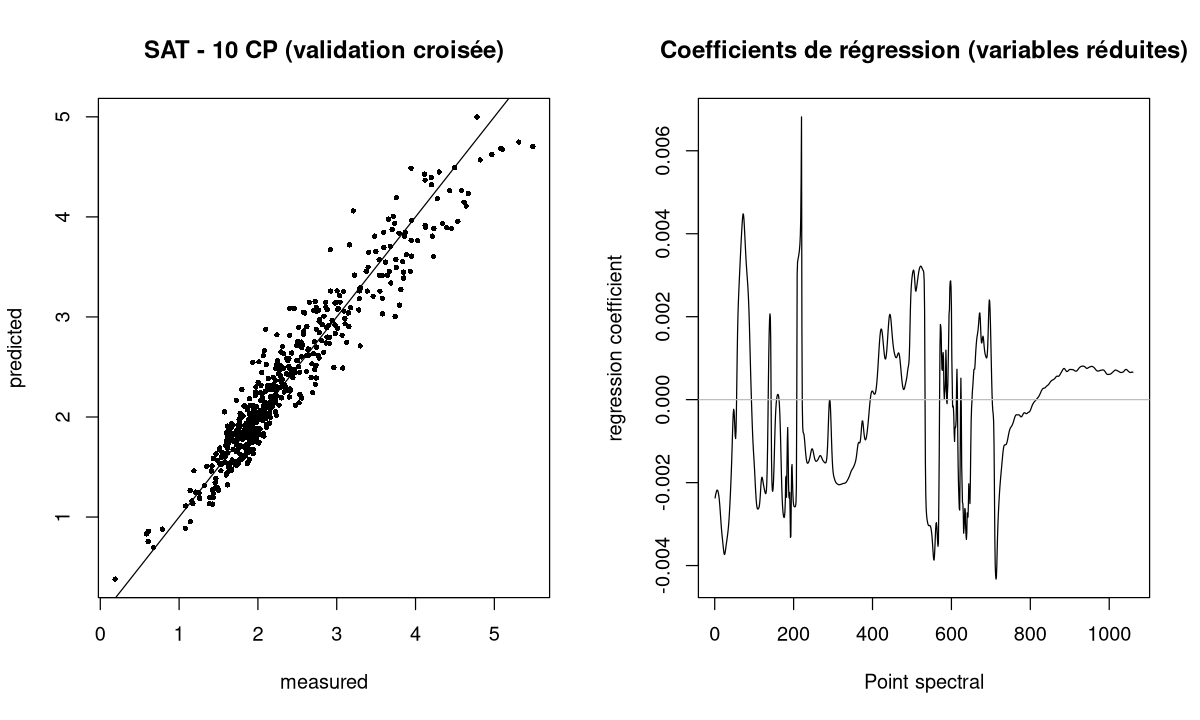

In [24]:
par(mfrow = c(1, 2))
predplot(PCR, ncomp = nPC_PCR, which = "validation", line = TRUE, pch = 16, cex = 0.6,
         main = paste("SAT -", nPC_PCR, "CP (validation croisée)"))
coefplot(PCR, ncomp = nPC_PCR, main = "Coefficients de régression (variables réduites)",
         xlab = "Point spectral")
par(mfrow = c(1, 1))

### 3.7.6 Une autre écriture : la matrice dans le `data.frame` (script `pcr_fatty_acids.R`)

Plutôt que de créer 1 060 colonnes nommées, le script `pcr_fatty_acids.R` stocke tout le spectre **comme une seule colonne-matrice** dans le data.frame. La formule devient alors `SAT ~ spectra`. C'est l'écriture recommandée dans la documentation du package `pls` : plus courte, et sans risque de mélanger y et les X.

In [25]:
dat <- data.frame(SAT = newy)
dat$spectra <- as.matrix(newX)       # une "colonne" qui contient une matrice 482 x 1060
dim(dat$spectra)

set.seed(1001)
PCR2 <- pcr(SAT ~ spectra, data = dat, scale = TRUE, validation = "CV", ncomp = 70)
# Mêmes résultats que le modèle précédent (même graine, mêmes données)
all.equal(RMSEP(PCR2, estimate = "CV")$val[1, 1, ], RMSEP(PCR, estimate = "CV")$val[1, 1, ],
          check.attributes = FALSE)

[1]  482 1060

[1] TRUE

> **Attention** : le script `pcr_fatty_acids.R` travaille sur les **485** échantillons (sans retirer les outliers GH), contrairement au Rmd (482). Ses résultats sont donc un peu différents.

### Exercice 3.4 : prédire avec le modèle retenu
1. Prédis la teneur en SAT des 5 premiers échantillons de `calibration` avec 10 composantes (`predict(PCR, newdata = ..., ncomp = 10)`). Quelle est la dimension de l'objet renvoyé ?
2. Compare avec les valeurs mesurées.
3. Que renvoie `predict(PCR, newdata = calibration[1:5, ])` sans préciser `ncomp` ?

In [26]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
p10 <- predict(PCR, newdata = calibration[1:5, ], ncomp = 10)
dim(p10)                                   # 5 x 1 x 1 : individus x réponses x modèles
round(cbind(mesure = calibration$SAT[1:5], predit = p10[, 1, 1]), 3)
dim(predict(PCR, newdata = calibration[1:5, ]))   # 5 x 1 x 70 : une prédiction par nb de composantes
```

`predict()` renvoie toujours un tableau à 3 dimensions. Sans `ncomp`, il contient les prédictions pour **tous** les modèles (1 à 70 composantes) : c'est ce qu'exploite le Rmd en partie 6 avec `predictionPCR[, , 10]`.

</details>

### Exercice 3.5 : l'équation finale sur les points spectraux
1. Extrais l'équation du modèle à 10 composantes sur les **variables d'origine** (intercept + 1 060 coefficients), en tenant compte du piège de `coef()` avec `scale = TRUE`.
2. Vérifie que `intercept + as.matrix(newX) %*% coefficients` redonne `predict(PCR, ncomp = 10)`.
3. Trace les coefficients d'origine le long du spectre.

In [27]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
b <- coef(PCR, ncomp = 10, intercept = TRUE)[, 1, 1]
b0 <- b[1]
b_orig <- b[-1] / PCR$scale                 # retour à l'échelle des absorbances
pred_main <- b0 + as.matrix(newX) %*% b_orig
all.equal(as.vector(pred_main), as.vector(predict(PCR, ncomp = 10)))
plot(b_orig, type = "l", col = "red", xlab = "Point spectral",
     ylab = "Coefficient (échelle d'origine)")
```

C'est cette équation (1 intercept + 1 060 coefficients) qui serait implémentée dans le spectromètre pour prédire SAT en routine. Les coefficients d'origine sont très grands là où les absorbances varient peu, puisqu'on a divisé par l'écart-type de chaque point.

</details>

### Exercice 3.6 : la PCR sans standardisation
Refais la PCR des acides gras avec `scale = FALSE` (même graine). Compare le R² de validation croisée à 10 composantes et le nombre de composantes du RMSE minimal. Pourquoi les résultats changent-ils ?

In [28]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
PCR_ns <- pcr(SAT ~ ., data = calibration, scale = FALSE, validation = "CV", ncomp = 70)
r2cv_ns <- R2(PCR_ns, estimate = "CV")$val[1, 1, -1]
rmse_ns <- RMSEP(PCR_ns, estimate = "CV")$val[1, 1, -1]
c(R2cv_10_scale = unname(r2_cv[10]), R2cv_10_noscale = unname(r2cv_ns[10]),
  ncomp_min_scale = unname(which.min(rmse_cv)), ncomp_min_noscale = unname(which.min(rmse_ns)))
```

Sans standardisation, le R² de validation croisée à 10 composantes chute de 0.92 à environ 0.38. L'ACP est dominée par les points spectraux de **grande variance** (les régions d'absorption intense ou bruitées) : les premières composantes décrivent ces régions, qu'elles soient liées ou non à SAT. Avec `scale = TRUE`, chaque point spectral a le même poids. Ni l'un ni l'autre n'est universellement meilleur ; le cours (et le Rmd) standardisent, comme pour les régressions pénalisées.

</details>

### Exercice 3.7 : PCR pour les acides gras mono-insaturés
Adapte la démarche à **MONO** (3e colonne de `fattyacid`), sur les mêmes échantillons nettoyés : modèle PCR (10-fold CV, 70 composantes, `set.seed(1001)`), tableau R²/RMSE pour 1 à 20 composantes, et choix du nombre de composantes avec la règle de l'*accuracy diff* (gain de R² de validation croisée inférieur à 0.001).

In [29]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
cal_mono <- data.frame(MONO = fattyacid$MONO[GH < 3], newX)
set.seed(1001)
PCR_mono <- pcr(MONO ~ ., data = cal_mono, scale = TRUE, validation = "CV", ncomp = 70)
r2cv_m <- R2(PCR_mono, estimate = "CV")$val[1, 1, ]
rmse_m <- RMSEP(PCR_mono, estimate = "CV")$val[1, 1, ]
gain <- c(NA, diff(r2cv_m))                       # accuracy diff
tab <- data.frame(R2_cv = round(100 * r2cv_m, 2), RMSE_cv = round(rmse_m, 4), gain = round(gain, 4))
tab[1:21, ]
which(gain[-1] < 0.001)[1]                        # premier nb de composantes dont l'apport est négligeable
```

La fonction `diff()` calcule directement les différences entre éléments consécutifs : c'est l'équivalent compact de la boucle `for` du Rmd.

`which(...)` renvoie 3 : la 3e composante n'apporte presque rien (gain de 0.0009). Appliquée **mécaniquement**, la règle retiendrait donc 2 composantes (R²cv = 76.4 %). Mais le tableau montre que les 6e et 11e composantes réapportent chacune environ 1 point de R² : une lecture attentive pourrait retenir 11 composantes (R²cv = 78.4 %). C'est le même arbitrage que fait le Rmd pour SAT : la règle stricte « gain < 0.001 » s'y arrêterait à 3 composantes, alors que le Rmd retient 10 composantes en regardant l'ensemble du tableau. Ces règles sont des **aides à la décision**, pas des automatismes.

</details>

---
## Questions de compréhension

**Q1.** Pourquoi la PCR n'a-t-elle pas de problème de colinéarité, alors que les variables explicatives d'origine sont très corrélées ?

**Q2.** Vrai ou faux : la PCR permet de construire une régression avec 1 060 variables et 482 observations.

**Q3.** Quelles sont les trois phases de la PCR ?

**Q4.** Quel est le principal inconvénient de la PCR ? Comment la PLS y répond-elle ?

**Q5.** Dans le tableau du Rmd, le RMSE de calibration de la PCR diminue toujours quand on ajoute des composantes. Pourquoi ne choisit-on pas 70 composantes ?

**Q6.** Que vaut l'indice à utiliser dans `RMSEP(PCR)$val[1, 1, ...]` pour lire la valeur à 10 composantes ?

<details>
<summary><b>Voir les réponses</b></summary>

**Q1.** Parce qu'elle utilise comme variables explicatives les **composantes principales**, qui sont orthogonales (non corrélées) par construction.

**Q2.** Vrai : on ne garde que $k$ composantes ($k \le n - 1$), et la régression porte sur ces $k$ variables. C'est un des deux avantages cités par le syllabus.

**Q3.** 1) ACP sur les variables explicatives ; 2) régression linéaire sur les composantes principales retenues ; 3) transformation inverse avec les vecteurs propres pour obtenir les coefficients des variables initiales.

**Q4.** La décomposition se fait sur la variabilité de **X**, sans regarder **y** : les composantes de grande variance ne sont pas forcément les plus prédictives. La PLS construit des variables latentes qui maximisent la **covariance avec y**.

**Q5.** Parce que la performance de **calibration** ne dit rien de la capacité à prédire de nouveaux échantillons. Le RMSE de validation croisée finit par remonter (surapprentissage), et les dernières composantes décrivent surtout du bruit.

**Q6.** 11, car la première position est le modèle « (Intercept) » à 0 composante. Ou bien on retire l'intercept avec `[-1]` et on prend la 10e valeur.

</details>

---
## Récapitulatif

- La **PCR** = ACP sur X (centrée réduite) + régression linéaire sur les $k$ premières composantes + retour aux variables d'origine via les vecteurs propres.
- Elle résout la **colinéarité** (composantes orthogonales) et fonctionne quand **p > n**. Son inconvénient : les composantes sont choisies selon la variance de **X**, pas selon leur lien avec **y**.
- Exemple octane : on retrouve la Table 2 du syllabus (5 composantes : 100 % de X, 99.25 % de y). La 7e composante, de variance nulle, n'a pas de sens.
- Le nombre de composantes se choisit par **validation croisée** : RMSE CV minimal, différence de robustesse (calibration − CV), différence de précision (gain entre deux modèles consécutifs), ou règles automatiques (`selectNcomp`).
- Acides gras (482 échantillons nettoyés) : la règle du Rmd retient **10 composantes** : R²cv = 92.21 %, RMSEcv = 0.238 g/dl, RPD ≈ 3.6.
- Piège : avec `scale = TRUE`, `coef()` renvoie les coefficients des variables **réduites** ; pour prédire, utiliser `predict()`.

| Fonction | Rôle |
|---|---|
| `pcr(y ~ ., data, ncomp, scale = TRUE, validation = "CV")` | régression sur composantes principales |
| `summary(m)`, `explvar(m)` | RMSEP de CV, % de variance de X et y |
| `R2(m, "all")`, `RMSEP(m, "all")` | performances train / CV / adjCV (`$val[estimate, response, model]`) |
| `validationplot(m, val.type, estimate)` | courbe RMSEP ou R2 selon le nb de composantes |
| `predplot(m, ncomp, which)` | prédits vs mesurés |
| `coefplot(m, ncomp)` | coefficients de régression |
| `predict(m, newdata, ncomp)` | prédictions (tableau 3D) |
| `selectNcomp(m, method)` | choix automatique du nb de composantes |
| `melt()` + `ggplot()` | graphiques du Rmd officiel |
| `diff(x)` | différences entre éléments consécutifs (*accuracy diff*) |

**Suite** : `04_Regression_PLS` : des variables latentes construites en tenant compte de y.